# When Apps Compete: Outliers, Ratings & Market Reach

A careful look at Google Play Store listings, where popularity is uneven, ratings are imperfect signals, and category-level comparisons can reveal more than a leaderboard of individual apps.

The analysis moves from raw-data quality to robust benchmarks. It keeps extreme values visible for investigation rather than automatically deleting them: a viral app may be unusual and still be a valid observation.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
import warnings


downloads = Path(r"C:\Users\anarrasulzada\Downloads")

file_path = next(
    file for file in downloads.rglob("*.csv")
    if "googleplaystore" in file.name.lower()
)

raw = pd.read_csv(file_path)

print(f"Dataset shape: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
display(raw.head())

Dataset shape: 10,841 rows × 13 columns


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


## A first quality scan

Before transforming values, inspect column types, missingness, repeated records, and suspicious category labels. This creates a baseline for judging whether the cleaning steps actually improved the data.

In [5]:
print("Column types")
display(raw.dtypes.rename("dtype").to_frame())

quality_before = pd.DataFrame({
    "missing values": raw.isna().sum(),
    "missing share (%)": (raw.isna().mean() * 100).round(2),
    "unique values": raw.nunique(dropna=True)
}).sort_values("missing share (%)", ascending=False)
display(quality_before)

print(f"Exact duplicate rows: {raw.duplicated().sum():,}")
print("Columns:", raw.columns.tolist())

Column types


,dtype
App,str
Category,str
Rating,float64
Reviews,str
Size,str
Installs,str
Type,str
Price,str
Content Rating,str
Genres,str


,missing values,missing share (%),unique values
Rating,1474,13.60,40
Current Ver,8,0.07,2832
Android Ver,3,0.03,33
Content Rating,1,0.01,6
Type,1,0.01,3
Size,0,0.00,462
Reviews,0,0.00,6002
Category,0,0.00,34
App,0,0.00,9660
Price,0,0.00,93


Exact duplicate rows: 483
Columns: ['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver']


## Clean the column names and remove structurally invalid rows

The source includes a known malformed record in which values are shifted across columns. Numeric parsing makes this detectable: a valid review count must be numeric, and a category should not look like a rating. Such records are excluded transparently before the main cleaning steps.

In [6]:
df = raw.copy()
df.columns = df.columns.str.strip()

required = {"App", "Category", "Rating", "Reviews", "Size", "Installs", "Type", "Price"}
missing_columns = required - set(df.columns)
if missing_columns:
    raise ValueError(f"Required columns are missing: {sorted(missing_columns)}")

for col in ["App", "Category", "Type"]:
    df[col] = df[col].astype("string").str.strip()

# identify rows where the reviews field is not an integer-like value
valid_reviews = df["Reviews"].astype("string").str.fullmatch(r"\s*\d+\s*", na=False)
invalid_review_rows = int((~valid_reviews).sum())
df = df.loc[valid_reviews].copy()

print(f"Structurally invalid rows removed: {invalid_review_rows:,}")
print(f"Rows remaining: {len(df):,}")

Structurally invalid rows removed: 1
Rows remaining: 10,840


## Numeric fields

Install counts are integer-like but stored as decorated strings. App size uses megabytes and kilobytes, while `Varies with device` is not a measurable fixed size. The conversion below standardizes size to MB and preserves unavailable measurements as missing.

In [7]:
df["Reviews"] = pd.to_numeric(df["Reviews"], errors="coerce").astype("Int64")

df["Installs"] = (
    df["Installs"].astype("string")
    .str.replace(",", "", regex=False)
    .str.replace("+", "", regex=False)
    .str.strip()
)
df["Installs"] = pd.to_numeric(df["Installs"], errors="coerce").astype("Int64")

def size_to_mb(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip()
    if value in {"", "Varies with device", "nan", "NaN"}:
        return np.nan
    try:
        if value.endswith("M"):
            return float(value[:-1])
        if value.endswith("k"):
            return float(value[:-1]) / 1000
        return float(value)
    except (TypeError, ValueError):
        return np.nan

df["Size"] = df["Size"].map(size_to_mb)

df["Price"] = (
    df["Price"].astype("string")
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)
df["Price"] = pd.to_numeric(df["Price"], errors="coerce")

df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")

# ratings outside the platform's 1–5 scale are invalid measurements
df.loc[~df["Rating"].between(1, 5), "Rating"] = np.nan
df.loc[df["Reviews"] < 0, "Reviews"] = pd.NA
df.loc[df["Installs"] < 0, "Installs"] = pd.NA
df.loc[df["Price"] < 0, "Price"] = np.nan

df["Type"] = df["Type"].replace({"0": "Free", "free": "Free", "paid": "Paid"})
df["Type"] = df["Type"].where(df["Type"].isin(["Free", "Paid"]))
df.loc[df["Price"].fillna(0).eq(0) & df["Type"].isna(), "Type"] = "Free"
df["Is Paid"] = df["Type"].eq("Paid")

display(df[["App", "Rating", "Reviews", "Size", "Installs", "Type", "Price"]].head(10))
print(df[["Rating", "Reviews", "Size", "Installs", "Price"]].dtypes)

,App,Rating,Reviews,Size,Installs,Type,Price
0,Photo Editor & Candy Camera & Grid & ScrapBook,4.1,159,19.0,10000,Free,0.0
1,Coloring book moana,3.9,967,14.0,500000,Free,0.0
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",4.7,87510,8.7,5000000,Free,0.0
3,Sketch - Draw & Paint,4.5,215644,25.0,50000000,Free,0.0
4,Pixel Draw - Number Art Coloring Book,4.3,967,2.8,100000,Free,0.0
5,Paper flowers instructions,4.4,167,5.6,50000,Free,0.0
6,Smoke Effect Photo Maker - Smoke Editor,3.8,178,19.0,50000,Free,0.0
7,Infinite Painter,4.1,36815,29.0,1000000,Free,0.0
8,Garden Coloring Book,4.4,13791,33.0,1000000,Free,0.0
9,Kids Paint Free - Drawing Fun,4.7,121,3.1,10000,Free,0.0


Rating      float64
Reviews       Int64
Size        float64
Installs      Int64
Price       Float64
dtype: object


## Resolve duplicate app listings

Multiple rows may describe the same app. For the benchmark dataset, retain the listing with the highest review count for each app. Sorting first makes the rule deterministic; exact duplicate rows are also removed. This is a pragmatic snapshot choice, not proof that the highest-review row is the newest version.

In [8]:
rows_before_dedup = len(df)
df = df.sort_values(["Reviews", "Installs"], ascending=[False, False], na_position="last")
df = df.drop_duplicates(subset=["App"], keep="first")
df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows before app-level deduplication: {rows_before_dedup:,}")
print(f"Rows after app-level deduplication:  {len(df):,}")
print(f"Duplicate app names remaining:       {df['App'].duplicated().sum():,}")

Rows before app-level deduplication: 10,840
Rows after app-level deduplication:  9,659
Duplicate app names remaining:       0


## Filling missing values without inventing precision

Ratings and sizes are imputed with their category median. Category medians are less sensitive to highly popular apps than means. If an entire category has no observed value for a metric, the global median is used as a final fallback. The notebook keeps flags for imputed values so the filled values remain auditable.

In [9]:
df["Rating was missing"] = df["Rating"].isna()
df["Size was missing"] = df["Size"].isna()

rating_global_median = df["Rating"].median()
size_global_median = df["Size"].median()

df["Rating"] = df["Rating"].fillna(df.groupby("Category")["Rating"].transform("median"))
df["Rating"] = df["Rating"].fillna(rating_global_median)

df["Size"] = df["Size"].fillna(df.groupby("Category")["Size"].transform("median"))
df["Size"] = df["Size"].fillna(size_global_median)

# retain rows where a market metric is unavailable rather than fabricating a value
print("Missing values after imputation")
display(df[["Rating", "Size", "Reviews", "Installs", "Price", "Type"]].isna().sum().rename("missing").to_frame())

print(f"Rating values imputed: {df['Rating was missing'].sum():,}")
print(f"Size values imputed:   {df['Size was missing'].sum():,}")

Missing values after imputation


,missing
Rating,0
Size,0
Reviews,0
Installs,0
Price,0
Type,0


Rating values imputed: 1,463
Size values imputed:   1,228


## Validation of the cleaned table

A cleaning pipeline should be tested, not just executed. These checks verify the expected data types, legal rating range, duplicate policy, and non-negative values. If an assertion fails, investigate the source data instead of silently continuing.

In [10]:
assert df["Rating"].dropna().between(1, 5).all(), "Rating range validation failed"
assert (df["Reviews"].dropna() >= 0).all(), "Negative review count remains"
assert (df["Installs"].dropna() >= 0).all(), "Negative install count remains"
assert (df["Price"].dropna() >= 0).all(), "Negative price remains"
assert not df["App"].duplicated().any(), "App-level duplicates remain"
assert pd.api.types.is_numeric_dtype(df["Reviews"]), "Reviews should be numeric"
assert pd.api.types.is_numeric_dtype(df["Installs"]), "Installs should be numeric"
assert pd.api.types.is_numeric_dtype(df["Size"]), "Size should be numeric"
assert pd.api.types.is_numeric_dtype(df["Price"]), "Price should be numeric"

print("Validation passed: numeric fields, ranges, and app-level uniqueness are consistent.")
display(df.describe(include="all").T.head(20))

Validation passed: numeric fields, ranges, and app-level uniqueness are consistent.


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
App,9659,9659,Facebook,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,9659,33,FAMILY,1874,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,9659.0,NaN,NaN,NaN,4.189523,0.496703,1.0,4.0,4.3,4.5,5.0
Reviews,9659.0,<NA>,<NA>,<NA>,216804.110363,1831430.21321,0.0,25.0,969.0,29453.5,78158306.0
Size,9659.0,NaN,NaN,NaN,19.430275,20.751588,0.0085,5.0,11.0,26.0,100.0
Installs,9659.0,<NA>,<NA>,<NA>,7798170.248162,53769728.818071,0.0,1000.0,100000.0,1000000.0,1000000000.0
Type,9659,2,Free,8905,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,9659.0,<NA>,<NA>,<NA>,1.097231,16.851618,0.0,0.0,0.0,0.0,400.0
Content Rating,9659,6,Everyone,7903,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Genres,9659,118,Tools,828,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## IQR outliers: reviews and installs

The interquartile range rule labels a value as an outlier when it falls below Q1 − 1.5×IQR or above Q3 + 1.5×IQR. Counts are calculated globally and within each category. These flags describe statistical rarity; they do not automatically mean the app record is erroneous.

In [11]:
def iqr_bounds(series):
    values = pd.to_numeric(series, errors="coerce").dropna()
    if values.empty:
        return np.nan, np.nan
    q1, q3 = values.quantile([0.25, 0.75])
    spread = q3 - q1
    return q1 - 1.5 * spread, q3 + 1.5 * spread

for metric in ["Reviews", "Installs"]:
    lower, upper = iqr_bounds(df[metric])
    df[f"{metric} outlier"] = df[metric].lt(lower) | df[metric].gt(upper)
    print(f"{metric}: lower fence={lower:,.2f}; upper fence={upper:,.2f}; "
          f"outliers={int(df[f'{metric} outlier'].sum()):,}")

outliers_by_category = (
    df.groupby("Category", observed=True)
    .agg(
        app_count=("App", "size"),
        review_outliers=("Reviews outlier", "sum"),
        install_outliers=("Installs outlier", "sum"),
        review_outlier_rate=("Reviews outlier", "mean"),
        install_outlier_rate=("Installs outlier", "mean")
    )
    .sort_values("review_outliers", ascending=False)
)
outliers_by_category[["review_outlier_rate", "install_outlier_rate"]] *= 100
display(outliers_by_category.round(2))

Reviews: lower fence=-44,117.75; upper fence=73,596.25; outliers=1,659
Installs: lower fence=-1,497,500.00; upper fence=2,498,500.00; outliers=1,981


,app_count,review_outliers,install_outliers,review_outlier_rate,install_outlier_rate
Category,,,,,
GAME,946,368,382,38.9,40.38
FAMILY,1874,258,301,13.77,16.06
TOOLS,829,135,174,16.28,20.99
PHOTOGRAPHY,281,101,124,35.94,44.13
COMMUNICATION,315,84,99,26.67,31.43
PRODUCTIVITY,374,77,91,20.59,24.33
SPORTS,325,66,74,20.31,22.77
SOCIAL,239,61,67,25.52,28.03
SHOPPING,202,53,72,26.24,35.64


## Visual: review outliers by category

A logarithmic y-axis makes the long-tailed distribution readable without removing the very large review counts. Category labels are rotated and the figure is saved with a descriptive filename.

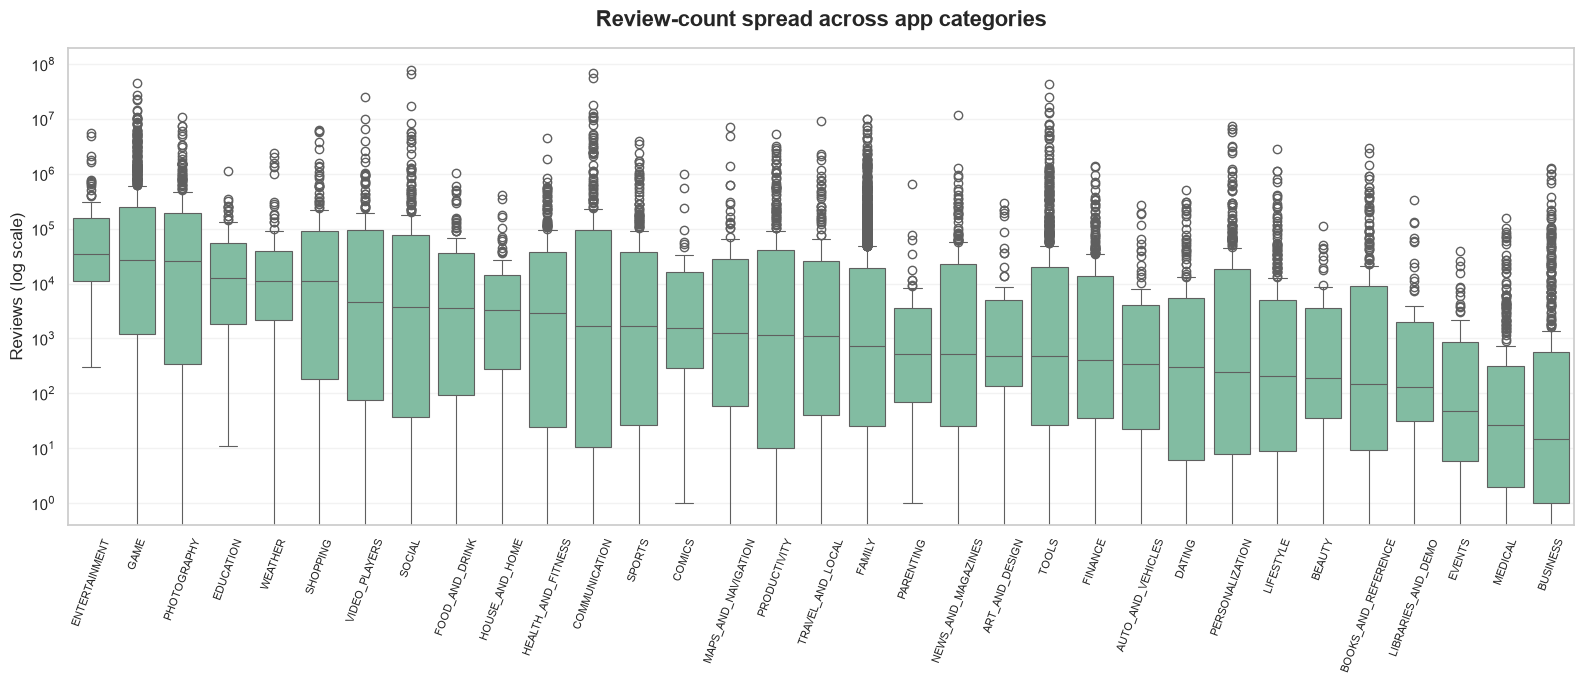

In [12]:
plot_data = df.loc[df["Reviews"].notna() & df["Category"].notna()].copy()
category_order = plot_data.groupby("Category")["Reviews"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(16, 7))
sns.boxplot(data=plot_data, x="Category", y="Reviews", order=category_order,
            showfliers=True, color="#78C6A3", linewidth=0.8, ax=ax)
ax.set_yscale("log")
ax.set_title("Review-count spread across app categories", pad=16, fontsize=16)
ax.set_xlabel("")
ax.set_ylabel("Reviews (log scale)")
ax.tick_params(axis="x", labelrotation=70, labelsize=8)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig("Outlier boxplot reviews by category.png", dpi=180, bbox_inches="tight")
plt.show()

## Category-level market benchmark

The median dampens the influence of a small number of blockbuster apps. The table combines central rating, install reach, review volume, app counts, and the free/paid mix. Install values remain in the source's rounded install buckets, so interpret them as approximate reach rather than exact active users.

In [13]:
category_benchmark = (
    df.groupby("Category", observed=True)
    .agg(
        app_count=("App", "nunique"),
        median_rating=("Rating", "median"),
        median_installs=("Installs", "median"),
        median_reviews=("Reviews", "median"),
        free_apps=("Type", lambda s: (s == "Free").sum()),
        paid_apps=("Type", lambda s: (s == "Paid").sum()),
        review_outliers=("Reviews outlier", "sum"),
        install_outliers=("Installs outlier", "sum")
    )
)
category_benchmark["free_share_pct"] = 100 * category_benchmark["free_apps"] / (
    category_benchmark["free_apps"] + category_benchmark["paid_apps"]
)
category_benchmark["paid_share_pct"] = 100 - category_benchmark["free_share_pct"]
category_benchmark = category_benchmark.sort_values(
    ["median_rating", "median_installs"], ascending=False
)
display(category_benchmark.round(2))

,app_count,median_rating,median_installs,median_reviews,free_apps,paid_apps,review_outliers,install_outliers,free_share_pct,paid_share_pct
Category,,,,,,,,,,
HEALTH_AND_FITNESS,288,4.5,100000.0,2882.5,273,15,49,56,94.79,5.21
BOOKS_AND_REFERENCE,222,4.5,10000.0,151.0,194,28,29,33,87.39,12.61
EVENTS,64,4.5,1000.0,47.0,63,1,0,2,98.44,1.56
EDUCATION,107,4.4,1000000.0,12733.0,104,3,20,20,97.20,2.80
ART_AND_DESIGN,61,4.4,100000.0,486.0,58,3,6,8,95.08,4.92
COMICS,56,4.4,100000.0,1576.5,56,0,4,5,100.00,0.00
PARENTING,60,4.4,100000.0,528.5,58,2,2,2,96.67,3.33
PERSONALIZATION,376,4.4,10000.0,242.5,295,81,48,66,78.46,21.54
GAME,946,4.3,1000000.0,26818.5,864,82,368,382,91.33,8.67


## Visual: median installs by category

The chart ranks categories by median installs, rather than total installs. This avoids allowing a category with many listings to dominate solely because it contains more apps.

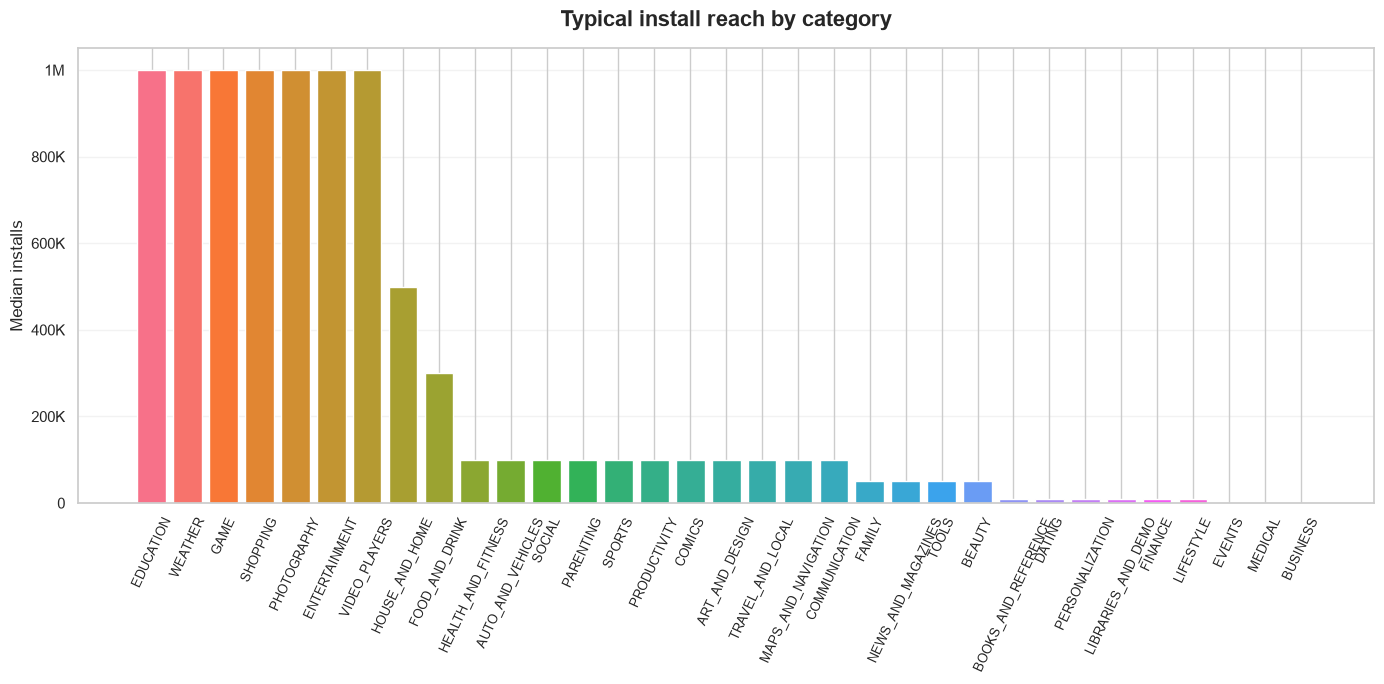

In [14]:
installs_plot = category_benchmark["median_installs"].dropna().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(14, 7))
bars = ax.bar(installs_plot.index, installs_plot.values, color=sns.color_palette("husl", len(installs_plot)))
ax.set_title("Typical install reach by category", fontsize=16, pad=16)
ax.set_ylabel("Median installs")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=65, labelsize=9)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1e6:.0f}M" if x >= 1e6 else f"{x/1e3:.0f}K" if x >= 1e3 else f"{x:.0f}"))
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig("Median installs by category.png", dpi=180, bbox_inches="tight")
plt.show()

## Free versus paid: compare medians, not means

Paid apps may have a different audience, pricing strategy, and selection bias. This comparison reports median rating, installs, and reviews. It also displays sample sizes so a small paid-app group is not mistaken for a stable market signal.

,app_count,median_rating,median_installs,median_reviews,mean_rating
Market type,,,,,
Free,8905,4.3,100000.0,1379.0,4.182
Paid,754,4.3,1000.0,88.5,4.274


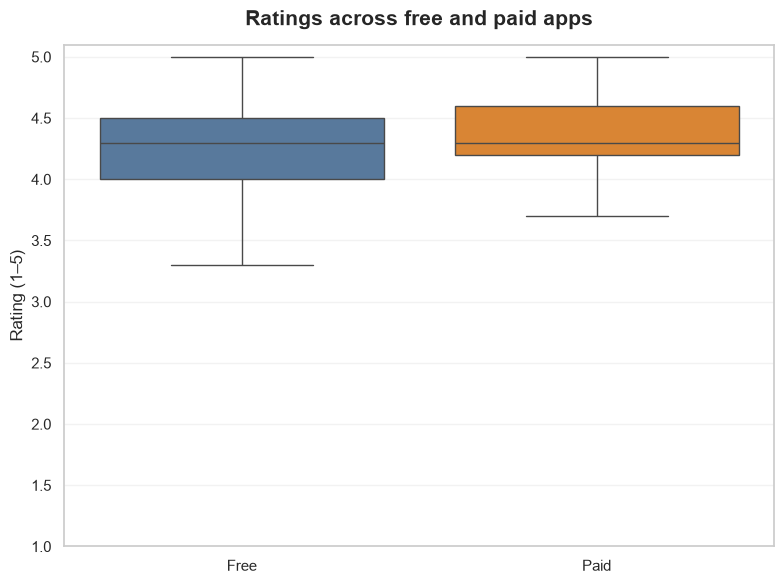

In [15]:
df["Market type"] = df["Type"].where(df["Type"].isin(["Free", "Paid"]))
free_paid_summary = (
    df[df["Market type"].notna()]
    .groupby("Market type")
    .agg(
        app_count=("App", "nunique"),
        median_rating=("Rating", "median"),
        median_installs=("Installs", "median"),
        median_reviews=("Reviews", "median"),
        mean_rating=("Rating", "mean")
    )
)
display(free_paid_summary.round(3))

fig, ax = plt.subplots(figsize=(8, 6))
sns.boxplot(data=df[df["Market type"].notna()], x="Market type", y="Rating",
            hue="Market type", palette={"Free": "#4C78A8", "Paid": "#F58518"},
            legend=False, showfliers=False, ax=ax)
ax.set_title("Ratings across free and paid apps", fontsize=15, pad=14)
ax.set_xlabel("")
ax.set_ylabel("Rating (1–5)")
ax.set_ylim(1, 5.1)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig("Free vs paid rating boxplot.png", dpi=180, bbox_inches="tight")
plt.show()

## Rating distributions before and after cleaning

The raw rating distribution includes missing and potentially invalid values; only valid numeric ratings can be shown. The cleaned distribution includes category-median imputations, which can create a small concentration at category medians. Read the two panels as a quality-impact check, not as two independent populations.

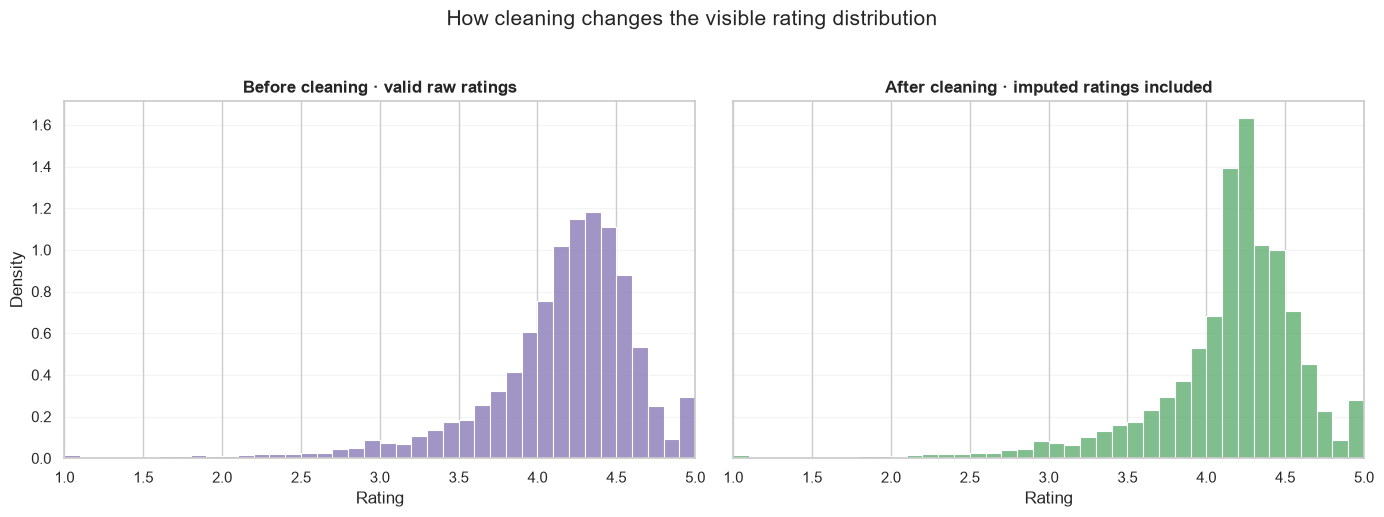

In [16]:
raw_rating = pd.to_numeric(raw["Rating"], errors="coerce")
raw_rating = raw_rating[raw_rating.between(1, 5)]
clean_rating = df["Rating"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
sns.histplot(raw_rating, bins=np.arange(1, 5.11, 0.1), stat="density",
             color="#8172B2", edgecolor="white", ax=axes[0])
axes[0].set_title("Before cleaning · valid raw ratings")
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("Density")
sns.histplot(clean_rating, bins=np.arange(1, 5.11, 0.1), stat="density",
             color="#55A868", edgecolor="white", ax=axes[1])
axes[1].set_title("After cleaning · imputed ratings included")
axes[1].set_xlabel("Rating")
axes[1].set_ylabel("")
for ax in axes:
    ax.set_xlim(1, 5)
    ax.grid(axis="y", alpha=0.2)
fig.suptitle("How cleaning changes the visible rating distribution", fontsize=15, y=1.03)
fig.tight_layout()
fig.savefig("Rating distribution before after cleaning.png", dpi=180, bbox_inches="tight")
plt.show()

## Bonus: category positioning map

This plot compares median rating with log-scaled median installs. Bubble size represents the number of apps in each category. The reference lines are the medians across categories, creating four broad positioning zones. The labels help identify categories that combine quality signals with market reach.

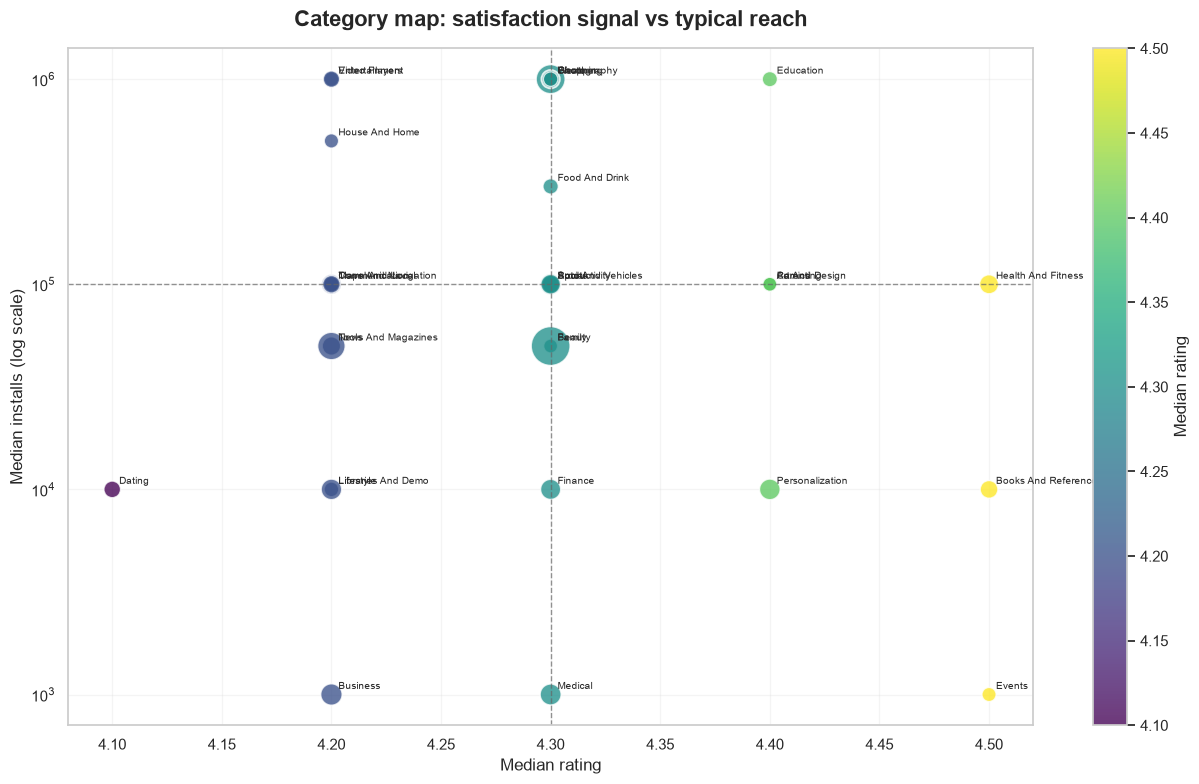

In [17]:
bubble = category_benchmark.dropna(subset=["median_rating", "median_installs"]).copy()
bubble = bubble[bubble["median_installs"] > 0]
x_mid = bubble["median_rating"].median()
y_mid = bubble["median_installs"].median()

fig, ax = plt.subplots(figsize=(13, 8))
sizes = 80 + 700 * bubble["app_count"] / bubble["app_count"].max()
scatter = ax.scatter(
    bubble["median_rating"], bubble["median_installs"],
    s=sizes, c=bubble["median_rating"], cmap="viridis",
    alpha=0.78, edgecolor="white", linewidth=1
)
ax.set_yscale("log")
ax.axvline(x_mid, linestyle="--", linewidth=1, color="#666666", alpha=0.7)
ax.axhline(y_mid, linestyle="--", linewidth=1, color="#666666", alpha=0.7)
for category, row in bubble.iterrows():
    ax.annotate(category.replace("_", " ").title(),
                (row["median_rating"], row["median_installs"]),
                xytext=(5, 4), textcoords="offset points", fontsize=7)
ax.set_title("Category map: satisfaction signal vs typical reach", fontsize=16, pad=16)
ax.set_xlabel("Median rating")
ax.set_ylabel("Median installs (log scale)")
ax.grid(alpha=0.2)
fig.colorbar(scatter, ax=ax, label="Median rating")
fig.tight_layout()
fig.savefig("Category rating and installs bubble map.png", dpi=180, bbox_inches="tight")
plt.show()

## Bonus: where paid apps appear to rate better

A positive rating gap is not automatically statistically significant. The following screen flags categories only when there are at least 10 observed ratings in both groups and the paid median is at least 0.15 rating points higher. This is a practical screening rule, not a hypothesis test or causal claim.

In [18]:
type_rating = (
    df[df["Type"].isin(["Free", "Paid"])]
    .groupby(["Category", "Type"], observed=True)
    .agg(app_count=("App", "nunique"), median_rating=("Rating", "median"))
    .reset_index()
)
wide = type_rating.pivot(index="Category", columns="Type", values="median_rating")
counts = type_rating.pivot(index="Category", columns="Type", values="app_count")
paid_gap = pd.DataFrame(index=wide.index)
paid_gap["free_median_rating"] = wide.get("Free")
paid_gap["paid_median_rating"] = wide.get("Paid")
paid_gap["paid_minus_free"] = paid_gap["paid_median_rating"] - paid_gap["free_median_rating"]
paid_gap["free_app_count"] = counts.get("Free")
paid_gap["paid_app_count"] = counts.get("Paid")
paid_gap["screen_flag"] = (
    paid_gap["paid_minus_free"].ge(0.15)
    & paid_gap["free_app_count"].ge(10)
    & paid_gap["paid_app_count"].ge(10)
)
paid_gap = paid_gap.sort_values("paid_minus_free", ascending=False)
display(paid_gap.round(3))
print("Categories meeting the practical paid-rating screen:")
display(paid_gap.loc[paid_gap["screen_flag"]].round(3))

,free_median_rating,paid_median_rating,paid_minus_free,free_app_count,paid_app_count,screen_flag
Category,,,,,,
NEWS_AND_MAGAZINES,4.2,4.80,0.60,252.0,2.0,False
ENTERTAINMENT,4.2,4.60,0.40,85.0,2.0,False
EDUCATION,4.4,4.70,0.30,104.0,3.0,False
ART_AND_DESIGN,4.4,4.70,0.30,58.0,3.0,False
SHOPPING,4.3,4.50,0.20,200.0,2.0,False
WEATHER,4.3,4.50,0.20,71.0,8.0,False
GAME,4.3,4.40,0.10,864.0,82.0,False
LIFESTYLE,4.2,4.30,0.10,350.0,19.0,False
VIDEO_PLAYERS,4.2,4.25,0.05,160.0,4.0,False


Categories meeting the practical paid-rating screen:


,free_median_rating,paid_median_rating,paid_minus_free,free_app_count,paid_app_count,screen_flag
Category,,,,,,


## Addition: correlations, quality effects, and category shortlist

A few extra checks add context to the core benchmark: Spearman correlations are more suitable than Pearson for skewed counts; imputation share indicates where category medians rely more heavily on filled ratings; and the shortlist combines above-median rating and installs with a minimum category size.

In [19]:
corr_data = df[["Rating", "Reviews", "Installs", "Size", "Price"]].apply(pd.to_numeric, errors="coerce")
display(corr_data.corr(method="spearman").round(3).style.background_gradient(cmap="vlag", vmin=-1, vmax=1))

category_benchmark["rating_above_category_median"] = category_benchmark["median_rating"] >= category_benchmark["median_rating"].median()
category_benchmark["installs_above_category_median"] = category_benchmark["median_installs"] >= category_benchmark["median_installs"].median()
category_benchmark["eligible_sample"] = category_benchmark["app_count"] >= 20

category_benchmark["performance_screen"] = (
    category_benchmark["rating_above_category_median"]
    & category_benchmark["installs_above_category_median"]
    & category_benchmark["eligible_sample"]
)
top_categories = category_benchmark.loc[category_benchmark["performance_screen"]].sort_values(
    ["median_rating", "median_installs"], ascending=False
).head(5)

print("Top categories with both above-median rating and installs (minimum 20 listings):")
display(top_categories[["app_count", "median_rating", "median_installs", "median_reviews", "free_share_pct"]].round(2))

imputation_by_category = df.groupby("Category", observed=True).agg(
    rating_imputation_pct=("Rating was missing", lambda s: 100 * s.mean()),
    size_imputation_pct=("Size was missing", lambda s: 100 * s.mean()),
    app_count=("App", "nunique")
).sort_values("rating_imputation_pct", ascending=False)
display(imputation_by_category.round(2).head(10))

,Rating,Reviews,Installs,Size,Price
Rating,1.000000,0.089000,0.011000,0.046000,0.074000
Reviews,0.089000,1.000000,0.968000,0.284000,-0.150000
Installs,0.011000,0.968000,1.000000,0.262000,-0.232000
Size,0.046000,0.284000,0.262000,1.000000,-0.042000
Price,0.074000,-0.150000,-0.232000,-0.042000,1.000000


Top categories with both above-median rating and installs (minimum 20 listings):


,app_count,median_rating,median_installs,median_reviews,free_share_pct
Category,,,,,
HEALTH_AND_FITNESS,288,4.5,100000.0,2882.5,94.79
EDUCATION,107,4.4,1000000.0,12733.0,97.20
ART_AND_DESIGN,61,4.4,100000.0,486.0,95.08
COMICS,56,4.4,100000.0,1576.5,100.00
PARENTING,60,4.4,100000.0,528.5,96.67


,rating_imputation_pct,size_imputation_pct,app_count
Category,,,
BUSINESS,37.38,10.48,420
EVENTS,29.69,10.94,64
MEDICAL,26.58,6.84,395
BOOKS_AND_REFERENCE,23.87,12.61,222
LIBRARIES_AND_DEMO,23.81,3.57,84
DATING,21.76,7.06,170
BEAUTY,20.75,11.32,53
PERSONALIZATION,20.74,6.65,376
SPORTS,20.00,12.31,325


## Five product-team takeaways

Use the results above to fill in a category-specific plan rather than treating a high rating as a guarantee of growth.

- **Find the overlap, not a single winner.** Prioritize categories that sit above the category-median lines for both rating and installs, while checking that their app counts are large enough to be informative.
- **Treat extreme reach as a distribution problem.** A category with many install outliers may have a few breakout products; its median describes a more typical listing than its mean.
- **Do not assume paid apps win.** Compare medians and sample sizes. The paid-rating screen is exploratory and cannot establish that charging causes better reviews.
- **Use review volume as context, not quality itself.** More reviews can signal reach and exposure, but rating and review count need not move together.
- **Invest in retention and differentiation.** Benchmark the category, then investigate what highly rated, widely installed apps offer in onboarding, reliability, content freshness, and user value. This dataset is a historical snapshot, so validate findings against current store data before making launch decisions.